#  Elastostatics Code using Quadratic Elements (ELQUABE)

A FORTRAN code for isotropic elasticity

The program allows for the traction values at both sides of the nodes connecting two elements to be different. For each particular $x_1$ or $x_2$ direction, (i) when both tractions are prescribed as different at both sides of the node the displacement is the only unknown; (ii) when the displacement and one traction is prescribed one on each side the other traction is the unknown and (iii) if only the displacement is prescribed, one value of the traction is the only unknown and this will be the same at both sides of the node.

# Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
ls

drive/  sample_data/


# Copy files from Drive to Colab

In [3]:
cp /content/drive/MyDrive/"Colab Notebooks"/BEM/Codigos_Livros/brebbia_dominguez/* .

cp: -r not specified; omitting directory '/content/drive/MyDrive/Colab Notebooks/BEM/Codigos_Livros/brebbia_dominguez/Pdf_BrebbiaDominguez'


In [4]:
ls

c            elquabe.for  pc12hf.dat   polinbe.for  pq10es.dat
drive/       eq06rp.dat   pl04hf.dat   pomcobe.for  RunCodes.ipynb
ec24cc.dat   eq12cb.dat   pl12hf.dat   poquabe.for  sample_data/
elconbe.for  eq12cc.dat   poconbe.for  pq05es.dat


# Compile the code ```elquabe.for```

In [5]:
!gfortran -std=legacy  -Wall  elquabe.for -o elquabe

elquabe.for:167:43:

  163 |       DO 40 I=1,N-1,2
      |                                                                        2
......
  167 |       CALL EXTINEQ(X(LL),Y(LL),X(I),Y(I),X(I+1),Y(I+1),X(I+2),Y(I+2),
      |                                           1
elquabe.for:167:50:

  163 |       DO 40 I=1,N-1,2
      |                                                                        2
......
  167 |       CALL EXTINEQ(X(LL),Y(LL),X(I),Y(I),X(I+1),Y(I+1),X(I+2),Y(I+2),
      |                                                  1
elquabe.for:167:57:

  163 |       DO 40 I=1,N-1,2
      |                                                                        2
......
  167 |       CALL EXTINEQ(X(LL),Y(LL),X(I),Y(I),X(I+1),Y(I+1),X(I+2),Y(I+2),
      |                                                         1
elquabe.for:167:64:

  163 |       DO 40 I=1,N-1,2
      |                                                                        2
......
  167 |       CALL EXTINEQ(X(LL),

In [6]:
ls

c            elquabe*     eq12cc.dat  poconbe.for  pq05es.dat
drive/       elquabe.for  pc12hf.dat  polinbe.for  pq10es.dat
ec24cc.dat   eq06rp.dat   pl04hf.dat  pomcobe.for  RunCodes.ipynb
elconbe.for  eq12cb.dat   pl12hf.dat  poquabe.for  sample_data/


# Install `gmsh`

In [7]:
!apt-get update
!apt-get install gmsh
!python -m pip install gmsh

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:4 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Get:6 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [75.3 kB]
Get:7 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:8 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,067 kB]
Get:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.4 MB]
Get:11 http://security.ubuntu.com/ubuntu noble-security/restricted amd64 Packages [2,122 kB]
Get:12 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/main amd64 Packages [60.1 kB]
Get:13 http://archive.ubuntu.com/ubuntu noble-backports InRe

# Install `meshio`

In [8]:
!pip install meshio[all]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.2/166.2 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 4.8 MB/s eta 0:00:00


# Gmsh geometry file (`.geo`)

In [9]:
%%writefile placa.geo
ref=1.;
L=1.;
W=1.;
Point(1) = {0, 0, 0, ref};
Point(2) = {L, 0, 0, ref};
Point(3) = {L, W, 0, ref};
Point(4) = {0, W, 0, ref};
Line(1) = {1, 2};
Line(2) = {2, 3};
Line(3) = {3, 4};
Line(4) = {4, 1};
Line Loop(1) = {1, 2, 3, 4};
Plane Surface(1) = {1};
Physical Curve("botton") = {1};
Physical Curve("right") = {2};
Physical Curve("top") = {3};
Physical Curve("left") = {4};
Physical Surface("surf1") = {1};

Writing placa.geo


# Generate mesh file (`.msh`) using Gmsh

In [10]:
!gmsh -2  placa.geo -o placa.msh  -order 2

Info    : Running '/usr/local/bin/gmsh -2 placa.geo -o placa.msh -order 2' [Gmsh 4.15.2, 1 node, max. 1 thread]
Info    : Started on Sun Oct 18 21:30:29 2026
Info    : Reading 'placa.geo'...
Info    : Done reading 'placa.geo'
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000561044s, CPU 0.000542s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.000862893s, CPU 0.000864s)
Info    : Meshing order 2 (curvilinear on)...
Info    : [  0%] Meshing curve 1 order 2
Info    : [ 30%] Meshing curve 2 order 2
Info    : [ 50%] Meshing curve 3 order 2
Info    : [ 70%] Meshing curve 4 order 2
Info    : [ 90%] Meshing surface 1 order 2
Info    : Surface mesh: worst distortion = 1 (0 elements in ]0, 0.2]); worst gamma = 0.828427
Info    : Done meshing order 2 (Wall 0.0001

In [11]:
import numpy as np
import meshio

def input_data():
    """
    This function defines input parameters for the Boundary Element Method (BEM)
    simulation applied to the plane elasticity equation with radial integration for domain
    integrals.

    Returns:
        dict: A dictionary containing the following key-value pairs:
            * bound_cond (dict): Boundary conditions for each edge:
                *
            * E (float): Material elastic modulus
            * nu (float): Poisson's ratio
            * file_name (str): Name of the .msh file (Gmsh mesh)
            * qpoint (str): String representing the coordinates of the heat source point
    """
    # Directly define values here for scripting (modify as needed)
    # Boundary conditions are specified in local coordinate system (normal-tangent)
    # type_x = type of the boundary condition in x direction
    # type_y = type of the boundary condition in y direction
    #    (type_x and type_y: 0 = displacement is know while 1 = traction is known)

    bound_cond = {'botton': {'type_x': 0, 'value_x': 0, 'type_y': 0, 'value_y': 0},
                  'right': {'type_x': 1, 'value_x': 0., 'type_y': 1, 'value_y': 0},
        'top': {'type_x': 1, 'value_x': 0, 'type_y': 1, 'value_y': 1},
        'left': {'type_x': 1, 'value_x': 0, 'type_y': 1, 'value_y': 0}
    }
    E = 1. # # Elastic modulus
    nu = 0. # Poisson ration
    file_name = 'placa'


    return {'bound_cond': bound_cond, 'E': E, 'nu': nu, 'file_name': file_name}

In [12]:
inp_data = input_data()
mesh = meshio.read(inp_data['file_name'] + '.msh')
line_elements = mesh.cells_dict

In [13]:
mesh.cells_dict

{'line3': array([[0, 1, 4],
        [1, 2, 5],
        [2, 3, 6],
        [3, 0, 7]]),
 'triangle6': array([[ 0,  1,  8,  4,  9, 10],
        [ 3,  0,  8,  7, 10, 11],
        [ 1,  2,  8,  5, 12,  9],
        [ 2,  3,  8,  6, 11, 12]])}

In [14]:
def compute_inodes(file_name, bound_cond):
    """
    This function reads a mesh file and extracts information about nodes, elements,
    and boundary conditions.

    Args:
      file_name: Name of the mesh file.
      bound_cond: Dictionary containing boundary conditions for each edge.

    Returns:
      A dictionary containing information about nodes, elements, and boundary
      conditions.
    """
    mesh = meshio.read(file_name + '.msh')
    coordinates = mesh.points
    line_elements = mesh.cells_dict['line3']
    triangle_elements = mesh.cells_dict['triangle6']
    segments = mesh.cell_data_dict['gmsh:physical']['line3']
    edges = mesh.field_data

    bc_info = {}
    for key, value in bound_cond.items():
        segment = mesh.field_data[key][0]
        bc_info[key] = {
            'type_x': value['type_x'],
            'value_x': value['value_x'],
            'segment': segment,
            'type_y': value['type_y'],
            'value_y': value['value_y'],
            'edge' : edges[key]
        }

    boundary_nodes = np.unique(line_elements)
    all_nodes = np.unique(triangle_elements)
    internal_nodes = [node for node in all_nodes if node not in boundary_nodes]

    return {
        'nodes': boundary_nodes,
        'internal_nodes': internal_nodes,
        'all_nodes': all_nodes,
        'coordinates': coordinates,
        'elements': line_elements,
        'triangles': triangle_elements,
        'segments': segments,
        'bc_info': bc_info
    }

In [15]:
def mount_bcs(segments, bc_info):
    """
    Constructs a boundary condition matrix from segment information and boundary condition data.

    This function takes a list of segment indices (`segments`) and a dictionary of boundary condition
    information (`bc_info`) to create a matrix (`bcs`) that stores the type and value of the boundary
    condition for each element.

    Args:
        segments (list or np.ndarray): A list or array of integers representing the indices of the boundary
                                       elements (segments) in the problem.
        bc_info (dict): A dictionary containing boundary condition information. The keys are typically
                        strings representing boundary condition names, and the values are dictionaries
                        with the following structure:
                        {
                            'type_x': bc_type,     # The type of boundary condition in x (0 for Dirichlet, 1 for Neumann)
                            'value_x': bc_value    # The value of the boundary condition in x (displacement or traction)
                            'segment': segment_index,  # The index of the segment this BC applies to
                            'type_y': bc_type,          # The type of boundary condition in y (0 for Dirichlet, 1 for Neumann)
                            'value_y': bc_value         # The value of the boundary condition in y (displacement or traction)
                        }

    Returns:
        bcs (np.ndarray): A 2D NumPy array where each row corresponds to a boundary element. The first
                         and third column contains the boundary condition type (0 or 1), and the second
                         and fourth column contains the boundary condition value.
    """

    num_elements = len(segments)

    # Initialize boundary condition matrix
    type_bcs = np.zeros((num_elements, 6), dtype=np.int64)
    val_bcs = np.zeros((num_elements, 6), dtype=np.float64)

    # Populate boundary condition matrix (bcs)
    for i, segment_index in enumerate(segments):
        # Find the boundary condition data corresponding to the current segment
        for bc_name, bc_data in bc_info.items():
            if bc_data['segment'] == segment_index:
                tp_x=bc_data['type_x']
                vl_x= bc_data['value_x']
                tp_y=bc_data['type_y']
                vl_y= bc_data['value_y']
                type_bcs[i,:] = np.array([tp_x,tp_y,tp_x,tp_y,tp_x,tp_y])
                val_bcs[i,:] = np.array([vl_x,vl_y,vl_x,vl_y,vl_x,vl_y])
                break  # Move on to the next segment once the BC is found
    return type_bcs,val_bcs

def comp_xyplot(elem, nodes):
    """
    Calculates the nodes and outward normal vector for each boundary element.

    This function takes element connectivity information (`elem`) and node coordinates (`nodes`)
    to determine the geometric center of each boundary element and the unit normal vector
    pointing outward from that element.

    Args:
        elem (np.ndarray): A 2D array defining the connectivity of the boundary elements.
                          Each row contains the indices of the two nodes that form an element.
                          Shape: (num_elements, 2).
        nodes (np.ndarray): A 2D array containing the coordinates (x, y) of each node in the mesh.
                           Shape: (num_nodes, 2).

    Returns:
        node_des (np.ndarray): A 2D array containing the coordinates (x, y) of the discontinuous nodes
                              of each boundary element. Shape: (2*num_elements, 2).
        normal (np.ndarray): A 2D array containing the unit outward normal vectors for each
                             boundary element. Shape: (num_elements, 2).
    """
    npp = 8                              # Number of plot points
    eta = np.linspace(-1., 1., npp)        # Plot points

    num_elements = elem.shape[0]

    xplot = np.zeros((num_elements,npp))        # Store x-coordinates for plotting
    yplot = np.zeros((num_elements,npp))        # Store y-coordinates for plotting


      # Define the local coordinates (xi) for nodes within a quadratic element
    xi = np.array([-1., 0., 1.])  # Gauss-Lobatto points for quadratic elements

    # Iterate over each boundary element
    for i in range(num_elements):
        # Get node indices for the current element
        node1, node3, node2 = elem[i]

        # Get coordinates of the two nodes forming the element
        x1, y1 = nodes[node1][0:2]
        x2, y2 = nodes[node2][0:2]
        x3, y3 = nodes[node3][0:2]

        # Iterate over Gauss points for numerical integration
        for k in range(npp):
            # Shape functions and their derivatives
            N1 = 0.5 * eta[k] * (eta[k] - 1)
            N2 = 1 - eta[k]**2
            N3 = 0.5 * eta[k] * (eta[k] + 1)

            # Calculate coordinates and normal vector at the Gauss point
            x, y = N1 * x1 + N2 * x2 + N3 * x3, N1 * y1 + N2 * y2 + N3 * y3
            ivet = npp * i + k  # Index for storing plot coordinates
            xplot[i,k], yplot[i,k] = x, y

    return xplot,yplot

In [16]:
def show_geometry(nodes,xplot,yplot,elem):
    xnode=nodes[:,0]
    ynode=nodes[:,1]
    ax = plt.axes()
    plt.plot(xnode[elem[:,0]],ynode[elem[:,0]],"gd",markersize=8)	# Plot the node of the elements
    plt.plot(xnode,ynode,"ro",markersize=2)	# Plot the node of the elements
    plt.axis("equal")

    n_el = elem.shape[0]
    for i in range(n_el):
        x=xplot[i,:]
        y=yplot[i,:]
        line_segments = LineCollection([list(zip(x, y))],
                                        linestyles='solid')
        ax.add_collection(line_segments)

    plt.show()

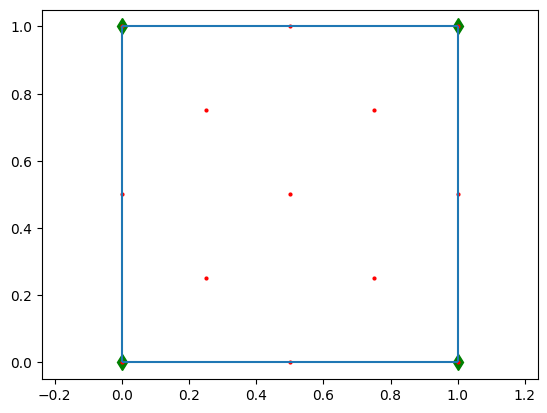

In [17]:
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
# Read information about input data
inp_data = input_data()
# Format input data
computed_data = compute_inodes(inp_data['file_name'], inp_data['bound_cond'])

# Generate bcs array with boundary conditions in each element
type_bcs,val_bcs = mount_bcs(computed_data['segments'], computed_data['bc_info'])

xplot,yplot = comp_xyplot(computed_data['elements'], computed_data['coordinates'])

show_geometry(computed_data['coordinates'],xplot,yplot,computed_data['elements'],)

# Create input file

In [18]:
import numpy as np

# Re-get the global `inp_data` dictionary to avoid shadowing
global_input_data = input_data()

inp_data_filename='eq12cb.dat'
int_points=computed_data['internal_nodes']

def format_coord(val):
    # Arredonda para evitar problemas de preciso numrica do Gmsh (ex: 2.999999999999 -> 3.0)
    val_rounded = round(val, 4)
    if val_rounded.is_integer():
        return f"{int(val_rounded)}."
    return f"{val_rounded}"

def create_input_file(filename, computed_data, int_points, \
                      type_bcs, val_bcs, input_params):
    """
    Creates an input file for the Fortran BEM program based on computed mesh data
    and boundary conditions.
    """
    with open(filename, 'w') as f:
        # 1. Title Line
        f.write("SQUARE PLATE UNDER TIME-HARMONIC TRACTION (4 QUADRATIC ELEMENTS)\n")

        # Extract data from computed_data and input_params
        nodes = computed_data['coordinates']
        elements = computed_data['elements']
        num_elements = elements.shape[0]
        num_internal_points = len(int_points)


        shear_modulus_real = input_params['E'] / (2 * (1 + input_params['nu']))

        poisson_ratio = input_params['nu']

        # 2. Basic Parameter Line (formatted to match squa4.dat)
        f.write(f" {num_elements},{num_internal_points},\
        {shear_modulus_real:.1f},{poisson_ratio:.2f}\n")

        # 3. Boundary Nodes Coordinates Lines
        # Sequncia geomtrica desejada: no1 e no_meio de cada elemento
        node_coords_list = []
        for elem in elements:
            no1_idx = elem[0]
            no_meio_idx = elem[2]
            x1, y1 = nodes[no1_idx][0], nodes[no1_idx][1]
            xm, ym = nodes[no_meio_idx][0], nodes[no_meio_idx][1]
            node_coords_list.append(f"{format_coord(x1)}  {format_coord(y1)}")
            node_coords_list.append(f"{format_coord(xm)}  {format_coord(ym)}")

        # Junta os pares usando o mesmo espaamento largo do arquivo squa4.dat original
        node_coords_str = "  ".join(node_coords_list)
        f.write("  " + node_coords_str + "\n")

        # 5. Boundary Conditions Lines
        for i in range(num_elements):
            # X and Y direction BCs for 3 nodes
            f.write(f"{type_bcs[i, 0]} {val_bcs[i, 0]:.1f} ")
            f.write(f"{type_bcs[i, 1]} {val_bcs[i, 1]:.1f} ")
            f.write(f"{type_bcs[i, 2]} {val_bcs[i, 2]:.1f} ")
            f.write(f"{type_bcs[i, 3]} {val_bcs[i, 3]:.1f} ")
            f.write(f"{type_bcs[i, 4]} {val_bcs[i, 4]:.1f} ")
            f.write(f"{type_bcs[i, 5]} {val_bcs[i, 5]:.1f} \n")

        # 6. Internal Points Coordinates Lines
        int_points_str = " ".join(f"{nodes[p][0]:.1f}  {nodes[p][1]:.1f}" for p in int_points)
        f.write(" " + int_points_str + "\n")



# Call the function with the correct arguments
create_input_file(inp_data_filename, computed_data, int_points, \
                  type_bcs, val_bcs, global_input_data)

# List input file

### The input file required by the program from the user contains the following lines of free format input:

* (i) Title Line Contains the title of the problem.

* (ii) Basic Parameter Lines Contains the number of elements, number of internal points, the shear modulus and the Poisson ratio (or fictitious Poisson's ratio for plane stress problems for which $v^{\prime}=v /(1+v)$ ).

* (iii) Boundary Nodes Coordinates Lines The coordinates are read counter-clockwise for external boundaries and clockwise for internal ones.

* (iv) Boundary Conditions Lines As many lines as boundary elements. Six values of KODE and the known variables are read for each element, corresponding to the three nodes and two directions per node. In this way, a value of a traction may be prescribed for a node as part of one element and a different value as part of the other element. The displacement however must be unique for any node. The variables are displacement if $\mathrm{KODE}=0$ or traction if $\mathrm{KODE}=1$.

* (v) Internal Points Coordinate Lines The $x_1 x_2$ coordinates for each point are read in free format. There will be one or more lines, if necessary, i.e. if internal points have been defined.


In [19]:
cat eq12cb.dat

SQUARE PLATE UNDER TIME-HARMONIC TRACTION (4 QUADRATIC ELEMENTS)
 4,5,        0.5,0.00
  0.  0.  0.5  0.  1.  0.  1.  0.5  1.  1.  0.5  1.  0.  1.  0.  0.5
0 0.0 0 0.0 0 0.0 0 0.0 0 0.0 0 0.0 
1 0.0 1 0.0 1 0.0 1 0.0 1 0.0 1 0.0 
1 0.0 1 1.0 1 0.0 1 1.0 1 0.0 1 1.0 
1 0.0 1 0.0 1 0.0 1 0.0 1 0.0 1 0.0 
 0.5  0.5 0.8  0.2 0.2  0.2 0.2  0.8 0.8  0.8


# Run `elquabe`

In [20]:
!./elquabe

 NAME OF INPUT FILE (MAX. 10 CHART.)
 NAME OF OUTPUT FILE (MAX. 10 CHART.)


In [21]:
ls

c            elquabe*     eq12cb.out  pl12hf.dat   polinbe.for  pq10es.dat
drive/       elquabe.for  eq12cc.dat  placa.geo    pomcobe.for  RunCodes.ipynb
ec24cc.dat   eq06rp.dat   pc12hf.dat  placa.msh    poquabe.for  sample_data/
elconbe.for  eq12cb.dat   pl04hf.dat  poconbe.for  pq05es.dat


# List output file

In [22]:
cat eq12cb.out

 *******************************************************************************
SQUARE PLATE UNDER TIME-HARMONIC TRACTION (4 QUADRATIC ELEMENTS)                


  DATA
  NUMBER OF BOUNDARY ELEMENTS=  4
  NUMBER OF INTERNAL POINTS=  5
  SHEAR MODULUS= 0.5000000E+00
  POISSON RATIO= 0.0000000E+00


  BOUNDARY NODES COORDINATES


    NODE          X                  Y

       1      0.0000000E+00      0.0000000E+00
       2      0.5000000E+00      0.0000000E+00
       3      0.1000000E+01      0.0000000E+00
       4      0.1000000E+01      0.5000000E+00
       5      0.1000000E+01      0.1000000E+01
       6      0.5000000E+00      0.1000000E+01
       7      0.0000000E+00      0.1000000E+01
       8      0.0000000E+00      0.5000000E+00


  BOUNDARY CONDITIONS

                                   PRESCRIBED VALUES
       -----FIRST NODE------   -----SECOND NODE-----   -----THIRD NODE------
 ELE   X DIR.  C   Y DIR.  C   X DIR.  C   Y DIR.  C   X DIR.  C   Y DIR.  C

   1    0.000  0   

In [26]:
tri

array([[ 0,  1,  8,  4,  9, 10],
       [ 3,  0,  8,  7, 10, 11],
       [ 1,  2,  8,  5, 12,  9],
       [ 2,  3,  8,  6, 11, 12]])

Arquivo 'resultado_temperatura.vtk' salvo com sucesso.
Imagem 'temperature_map.png' salva com sucesso.


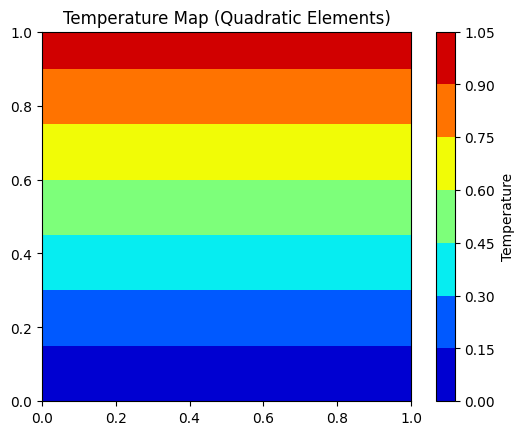

In [27]:
import numpy as np
import meshio
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib import cm

coord = computed_data['coordinates']
tri6 = computed_data['triangles']
Temperature = coord[:, 1]  # Temperature = Y

# 1. Exportando usando meshio (suporta elementos quadráticos nativamente)
cells = [("triangle6", tri6)]
mesh_out = meshio.Mesh(coord, cells, point_data={"Temperature": Temperature})
meshio.write("resultado_temperatura.vtk", mesh_out)
print("Arquivo 'resultado_temperatura.vtk' salvo com sucesso.")

# 2. Salvando a imagem em PNG com Matplotlib
# Para plotar elementos de 6 nós no matplotlib, subdividimos cada triângulo quadrático em 4 triângulos lineares.
# Índices de um triângulo de 6 nós tipicamente: 0, 1, 2 (vértices), 3, 4, 5 (meios das arestas).
# Gmsh triangle6: 0, 1, 2 (vértices), 3 (aresta 0-1), 4 (aresta 1-2), 5 (aresta 2-0).
tri3_list = []
for t in tri6:
    v0, v1, v2, v3, v4, v5 = t
    tri3_list.append([v0, v3, v5])
    tri3_list.append([v3, v1, v4])
    tri3_list.append([v5, v4, v2])
    tri3_list.append([v3, v4, v5])

tri3_array = np.array(tri3_list)

fig, ax = plt.subplots()
triang = mtri.Triangulation(coord[:, 0], coord[:, 1], tri3_array)

ax.triplot(triang, color=(0.0, 0., 0.), linewidth=0.4)
contourf = ax.tricontourf(triang, Temperature, cmap=cm.jet)
fig.colorbar(contourf, ax=ax, label="Temperature")

ax.set_title("Temperature Map (Quadratic Elements)")
ax.set_aspect("equal")

plt.savefig("temperature_map.png", dpi=300, bbox_inches='tight')
print("Imagem 'temperature_map.png' salva com sucesso.")
plt.show()